## Simulação de reunião

##### Frases longas que simulam uma reunião sobre um único projeto

In [1]:
import numpy as np
from sentence_transformers import SentenceTransformer


sentences = [
    "Pessoal, eu queria começar revisando rapidamente o status do projeto, porque na última reunião a gente ficou de alinhar melhor o cronograma com as entregas do time de engenharia.",
    "Certo, eu dei uma olhada nos últimos relatórios e percebi que algumas tarefas críticas ainda não foram concluídas, principalmente aquelas relacionadas à integração com o sistema externo.",
    "Isso, e além disso a gente teve alguns bloqueios técnicos que não estavam previstos, o que acabou impactando diretamente o tempo de desenvolvimento.",
    
    "Entendi, então talvez faça sentido a gente revisar o cronograma inteiro, porque não adianta manter uma data que já não é mais realista.",
    "Concordo, mas antes disso acho importante entender quais dessas tarefas realmente são prioritárias para a entrega mínima.",
    "Sim, porque se a gente tentar entregar tudo ao mesmo tempo, provavelmente vamos atrasar ainda mais.",
    
    "Então vamos fazer o seguinte, vamos listar o que é essencial para a primeira versão e o que pode ficar para depois.",
    "Do ponto de vista técnico, a integração com o sistema externo é obrigatória, senão o produto nem funciona direito.",
    "E do lado de produto, a funcionalidade de relatórios pode ser simplificada na primeira entrega.",
    
    "Perfeito, então já temos uma primeira separação de prioridades.",
    "Agora, tem um outro ponto que a gente precisa discutir, que é o orçamento, porque essas mudanças podem impactar custo também.",
    "Verdade, principalmente se a gente precisar de mais tempo de desenvolvimento ou contratar apoio externo.",
    
    "Sobre orçamento, vocês têm alguma estimativa atualizada considerando esses atrasos?",
    "Ainda não fechamos um número exato, mas já sabemos que vamos extrapolar o que foi planejado inicialmente.",
    "E isso pode ser um problema, porque o financeiro já sinalizou que não há muita margem para aumento.",
    
    "Então talvez a gente precise compensar reduzindo escopo, ao invés de aumentar custo.",
    "Isso faz sentido, principalmente se focarmos só no que é essencial agora.",
    "Concordo, mas precisamos tomar cuidado para não comprometer a experiência do usuário.",
    
    "Certo, então vamos alinhar o seguinte: priorizar o essencial, reduzir o escopo e manter o orçamento sob controle.",
    "Com isso, acho que conseguimos ajustar o cronograma também, mesmo que com uma nova data de entrega.",
    "E podemos comunicar isso de forma transparente para os stakeholders.",
    
    "Falando nisso, quem vai ficar responsável por atualizar os stakeholders sobre essas mudanças?",
    "Eu posso preparar a parte técnica, explicando os motivos do atraso.",
    "E eu posso cuidar da comunicação mais estratégica, explicando impacto e próximos passos.",
    
    "Ótimo, então fechamos assim.",
    "Só mais um ponto, precisamos definir checkpoints semanais para garantir que não vamos desviar novamente.",
    "Concordo totalmente, isso ajuda a identificar problemas mais cedo.",
    
    "Então vamos agendar reuniões rápidas semanais, só para acompanhamento.",
    "Pode ser algo de 15 minutos, só para status mesmo.",
    "Perfeito, isso mantém todo mundo alinhado sem tomar muito tempo.",
    
    "Então, recapitulando, vamos revisar o cronograma, ajustar o escopo, manter o orçamento e melhorar o acompanhamento.",
    "E também garantir que a comunicação com stakeholders seja feita de forma clara.",
    "E que todo mundo esteja alinhado com as prioridades certas.",
    
    "Se não tiver mais nada, acho que podemos encerrar por aqui.",
    "Por mim está tudo certo.",
    "Também acho, foi bem produtivo."
]
sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1366.16it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(36, 768)
[[ 0.0182465   0.03280974 -0.02634596 ... -0.02907525 -0.02245243
   0.03813311]
 [ 0.0264254   0.03911427 -0.02330067 ... -0.03377688 -0.0159133
   0.04328023]
 [ 0.02587654  0.03973934 -0.01973963 ... -0.0398706  -0.0162422
   0.03243197]
 ...
 [ 0.00996005  0.02105916 -0.0227904  ... -0.05758267 -0.05329507
   0.02747583]
 [ 0.01888879  0.03288854 -0.03835019 ... -0.05374489 -0.04336422
   0.03844331]
 [ 0.03945308  0.03055353 -0.03230348 ... -0.05093595 -0.03121357
   0.03122642]]


In [15]:
from sklearn.metrics.pairwise import cosine_similarity

scores = cosine_similarity(S)

n = len(sentences_e5)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i: 
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.97264236 0.         0.         ... 0.         0.         0.        ]
 [0.97335064 0.97365832 0.         ... 0.         0.         0.        ]
 ...
 [0.94592863 0.94471252 0.94597626 ... 0.         0.         0.        ]
 [0.88863206 0.88386822 0.87625444 ... 0.90170616 0.         0.        ]
 [0.94434965 0.94544482 0.94544017 ... 0.93484735 0.90744162 0.        ]]


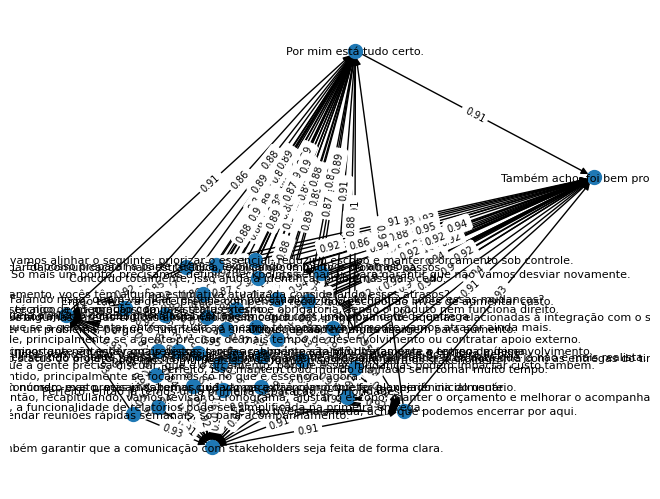

In [16]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

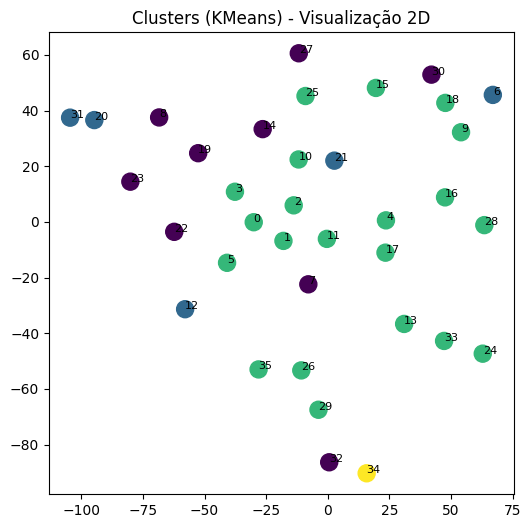

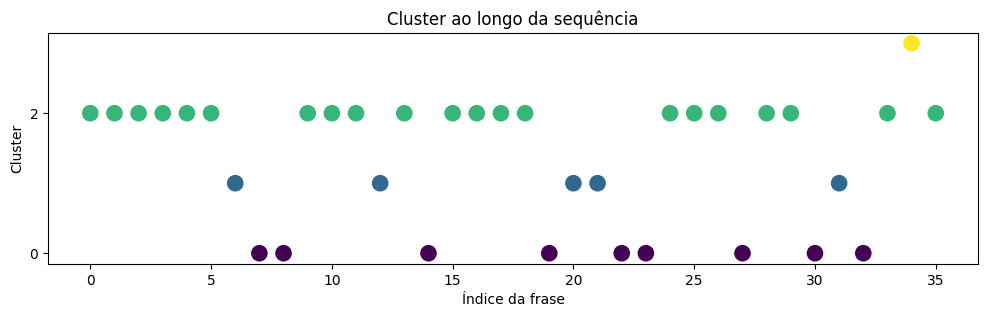

In [20]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

S_norm = normalize(S)

kmeans = KMeans(n_clusters=4, random_state=0)
labels = kmeans.fit_predict(S_norm)

tsne = TSNE(n_components=2, random_state=0, perplexity=5)
S_2d = tsne.fit_transform(S_norm)


plt.figure(figsize=(6,6))
plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=150)

for i in range(len(sentences)):
    plt.text(S_2d[i,0], S_2d[i,1], str(i), fontsize=8)

plt.title("Clusters (KMeans) - Visualização 2D")
plt.show()

plt.figure(figsize=(12,3))
plt.scatter(range(len(sentences)), labels, c=labels, s=120)

plt.yticks([0,2])
plt.xlabel("Índice da frase")
plt.ylabel("Cluster")
plt.title("Cluster ao longo da sequência")

plt.show()

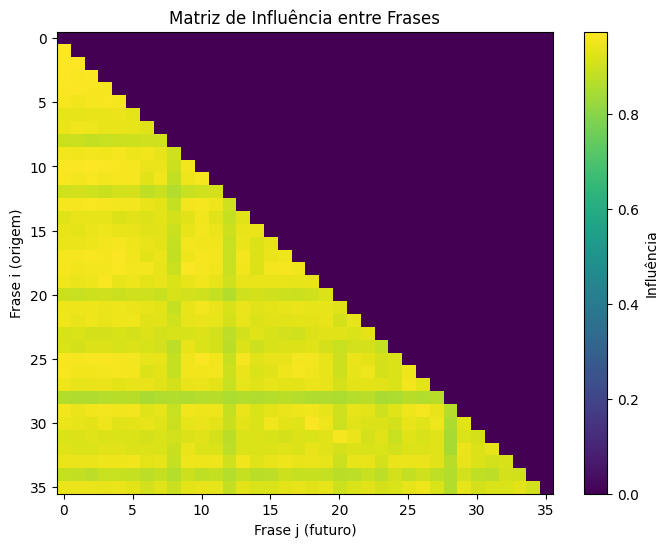

In [28]:
plt.figure(figsize=(8,6))
plt.imshow(A, cmap="viridis", aspect="auto")
plt.colorbar(label="Influência")
plt.title("Matriz de Influência entre Frases")
plt.xlabel("Frase j (futuro)")
plt.ylabel("Frase i (origem)")
plt.show()


 Segmentos detectados:


--- Segmento 1 (0 → 7) ---
- Pessoal, eu queria começar revisando rapidamente o status do projeto, porque na última reunião a gente ficou de alinhar melhor o cronograma com as entregas do time de engenharia.
- Certo, eu dei uma olhada nos últimos relatórios e percebi que algumas tarefas críticas ainda não foram concluídas, principalmente aquelas relacionadas à integração com o sistema externo.
- Isso, e além disso a gente teve alguns bloqueios técnicos que não estavam previstos, o que acabou impactando diretamente o tempo de desenvolvimento.
- Entendi, então talvez faça sentido a gente revisar o cronograma inteiro, porque não adianta manter uma data que já não é mais realista.
- Concordo, mas antes disso acho importante entender quais dessas tarefas realmente são prioritárias para a entrega mínima.
- Sim, porque se a gente tentar entregar tudo ao mesmo tempo, provavelmente vamos atrasar ainda mais.
- Então vamos fazer o seguinte, vamos listar o que é essencial

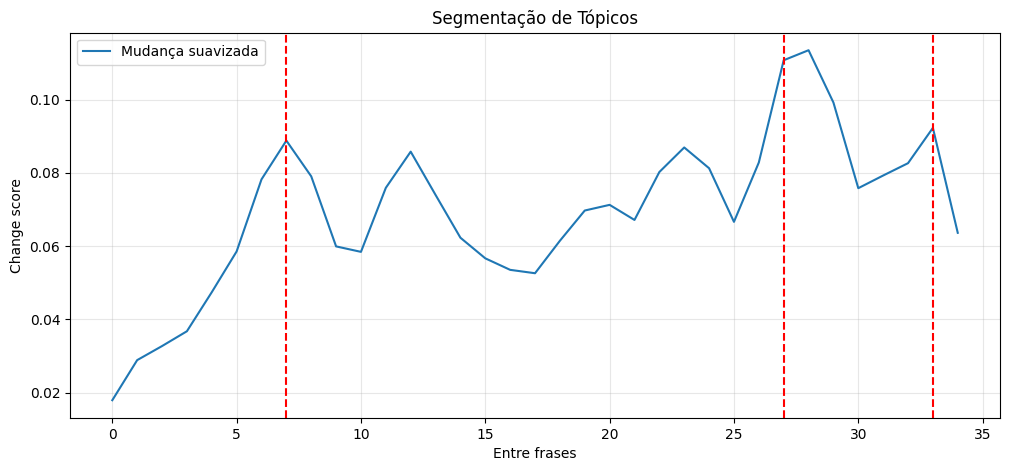

In [41]:
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

S_norm = normalize(S)
n = len(S_norm)

adj_sim = np.array([
    cosine_similarity(S_norm[i].reshape(1, -1), S_norm[i+1].reshape(1, -1))[0, 0]
    for i in range(n - 1)
])

change = 1 - adj_sim

# suavização
window = 3
kernel = np.ones(window) / window
change_smooth = np.convolve(change, kernel, mode='same')

threshold = np.mean(change_smooth) + 0.87 * np.std(change_smooth)

split_points = np.where(change_smooth > threshold)[0]

min_distance = 2
filtered_splits = []

for idx in split_points:
    if not filtered_splits or idx - filtered_splits[-1] > min_distance:
        filtered_splits.append(idx)

split_points = filtered_splits

segments = []
start = 0

for idx in split_points:
    segments.append((start, idx+1))
    start = idx+1

segments.append((start, n))

print("\n Segmentos detectados:\n")

for i, (s, e) in enumerate(segments):
    print(f"\n--- Segmento {i+1} ({s} → {e-1}) ---")
    for sent in sentences[s:e]:
        print("-", sent)


print("\n Rótulos dos segmentos:\n")

for i, (s, e) in enumerate(segments):
    mid = (s + e) // 2
    print(f"Segmento {i+1}: {sentences[mid]}")


plt.figure(figsize=(12,5))

plt.plot(change_smooth, label="Mudança suavizada")

for idx in split_points:
    plt.axvline(idx, color='red', linestyle='--')

plt.title("Segmentação de Tópicos")
plt.xlabel("Entre frases")
plt.ylabel("Change score")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

O modelo não separa os tópicos esperados pois todos pertencem ao mesmo domínio semântico. As mudanças observadas são estruturais e não representam uma ruptura significativa no espaço de embeddings.